In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

df = pd.read_csv(
    "../output/online_retail_clean_backup.csv",
    parse_dates=["InvoiceDate"],
    dtype={
        "Invoice": "string",
        "Customer ID": "string",
        "StockCode": "string"
    }
)

print("- KIỂM TRA DỮ LIỆU -")
print("Số dòng:", len(df))
print("Số khách hàng:", df["Customer ID"].nunique())
print("Số hóa đơn:", df["Invoice"].nunique())
print("Ngày đầu:", df["InvoiceDate"].min())
print("Ngày cuối:", df["InvoiceDate"].max())
print("Tổng giá trị giao dịch (GBP):", round(df["LineTotal"].sum(), 2))

- KIỂM TRA DỮ LIỆU -
Số dòng: 779425
Số khách hàng: 5878
Số hóa đơn: 36969
Ngày đầu: 2009-12-01 07:45:00
Ngày cuối: 2011-12-09 12:50:00
Tổng giá trị giao dịch (GBP): 17374804.27


In [2]:
df["YearMonth"] = (
    df["InvoiceDate"]
    .dt.to_period("M")
    .astype(str)
)

monthly_summary = (
    df.groupby("YearMonth")
    .agg(
        Revenue=("LineTotal", "sum"),
        Orders=("Invoice", "nunique"),
        Active_Customers=("Customer ID", "nunique")
    )
    .reset_index()
    .sort_values("YearMonth")
)

monthly_summary["Revenue"] = monthly_summary["Revenue"].round(2)

print("- HOẠT ĐỘNG GIAO DỊCH THEO THÁNG -")
print(monthly_summary.to_string(index=False))

- HOẠT ĐỘNG GIAO DỊCH THEO THÁNG -
YearMonth    Revenue  Orders  Active_Customers
  2009-12  683504.01    1512               955
  2010-01  555802.67    1011               720
  2010-02  504558.96    1104               772
  2010-03  696978.47    1524              1057
  2010-04  591982.00    1329               942
  2010-05  597833.38    1377               966
  2010-06  636371.13    1497              1041
  2010-07  589736.17    1381               928
  2010-08  602224.60    1293               911
  2010-09  829013.95    1689              1145
  2010-10 1033112.01    2133              1497
  2010-11 1166460.02    2587              1607
  2010-12  570422.73    1400               885
  2011-01  568101.31     987               741
  2011-02  446084.92     997               758
  2011-03  594081.76    1321               974
  2011-04  468374.33    1149               856
  2011-05  677355.15    1555              1056
  2011-06  660046.05    1393               991
  2011-07  598962.90    1

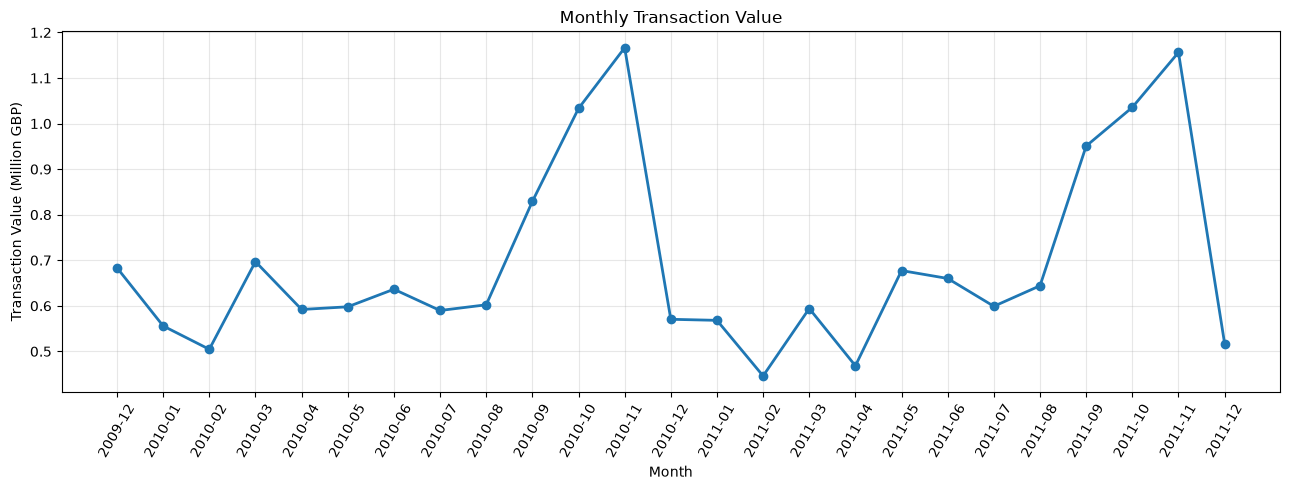

In [7]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    monthly_summary["YearMonth"],
    monthly_summary["Revenue"],
    marker="o",
    linewidth=2
)

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x / 1_000_000:.1f}")
)

ax.set_title("Monthly Transaction Value")
ax.set_xlabel("Month")
ax.set_ylabel("Transaction Value (Million GBP)")

ax.tick_params(axis="x", rotation=60)
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../output/monthly_transaction_value.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [4]:
# Tính tổng giá trị của từng hóa đơn
invoice_summary = (
    df.groupby("Invoice", as_index=False)
    .agg(
        OrderValue=("LineTotal", "sum"),
        CustomerID=("Customer ID", "first")
    )
)

total_revenue = df["LineTotal"].sum()
total_orders = len(invoice_summary)

aov = total_revenue / total_orders

print("- CHỈ TIÊU GIAO DỊCH TỔNG QUAN -")
print("Tổng giá trị giao dịch (GBP):", round(total_revenue, 2))
print("Tổng hóa đơn:", total_orders)
print("Tổng khách hàng:", df["Customer ID"].nunique())
print("AOV (GBP):", round(aov, 2))

print("\n- PHÂN PHỐI GIÁ TRỊ HÓA ĐƠN -")
print(
    invoice_summary["OrderValue"]
    .describe()
    .round(2)
    .to_string()
)

- CHỈ TIÊU GIAO DỊCH TỔNG QUAN -
Tổng giá trị giao dịch (GBP): 17374804.27
Tổng hóa đơn: 36969
Tổng khách hàng: 5878
AOV (GBP): 469.98

- PHÂN PHỐI GIÁ TRỊ HÓA ĐƠN -
count     36969.00
mean        469.98
std        1359.74
min           0.38
25%         157.92
50%         303.04
75%         477.28
max      168469.60


In [5]:
customer_orders = (
    df.groupby("Customer ID")["Invoice"]
    .nunique()
)

one_time_customers = (customer_orders == 1).sum()
repeat_customers = (customer_orders >= 2).sum()

print("- HÀNH VI MUA LẶP LẠI -")
print("Khách hàng mua 1 lần:", one_time_customers)
print("Khách hàng mua từ 2 lần:", repeat_customers)

print(
    "Tỷ lệ khách hàng mua lặp lại:",
    round(repeat_customers / len(customer_orders) * 100, 2),
    "%"
)

- HÀNH VI MUA LẶP LẠI -
Khách hàng mua 1 lần: 1623
Khách hàng mua từ 2 lần: 4255
Tỷ lệ khách hàng mua lặp lại: 72.39 %
